# Diagnostics and robustness
Forecast diagnostics, overlay ablation, deflated Sharpe and parameter sensitivity.

In [1]:
import sys

sys.path.insert(0, "..")
import pandas as pd
import config

P = config.PATHS
pd.read_csv(P.tables / "regime_return_link.csv")

,Asset,Window,n,CorrStressNextRet,MeanRetStressed,MeanRetCalm,StressedMonths
0,BTC-USD,initial_window,48,-0.151107,-0.032730,0.105925,11
1,BTC-USD,after,83,0.185886,0.060300,0.006247,32
2,DBC,initial_window,48,-0.143095,0.002748,0.011810,39
3,DBC,after,187,0.172580,0.003883,0.000460,51
4,EFA,initial_window,48,-0.323734,-0.024214,0.015582,24
5,EFA,after,211,0.197683,0.015288,0.003461,69
6,ETH-USD,initial_window,48,0.042775,0.045349,0.040283,28
7,ETH-USD,after,46,0.318039,0.092260,-0.010276,9
8,GLD,initial_window,48,-0.029545,0.016643,0.020769,34
9,GLD,after,201,0.120127,0.005890,0.006439,59


In [2]:
pd.read_csv(P.tables / "ic_diagnostics_summary.csv", index_col=0)

,MeanIC,MeanIC_equities,MeanR2OOS,AssetsPositiveIC,Assets
Variant,,,,,
as_specified,-0.008210,-0.085272,-0.063536,3,9
no_regime_features,-0.033897,-0.096637,-0.069613,3,9
no_stress_features,0.017640,-0.048448,-0.049841,6,9
longer_initial_window,-0.008210,-0.085272,-0.063536,3,9
no_regime_longer_window,-0.033897,-0.096637,-0.069613,3,9


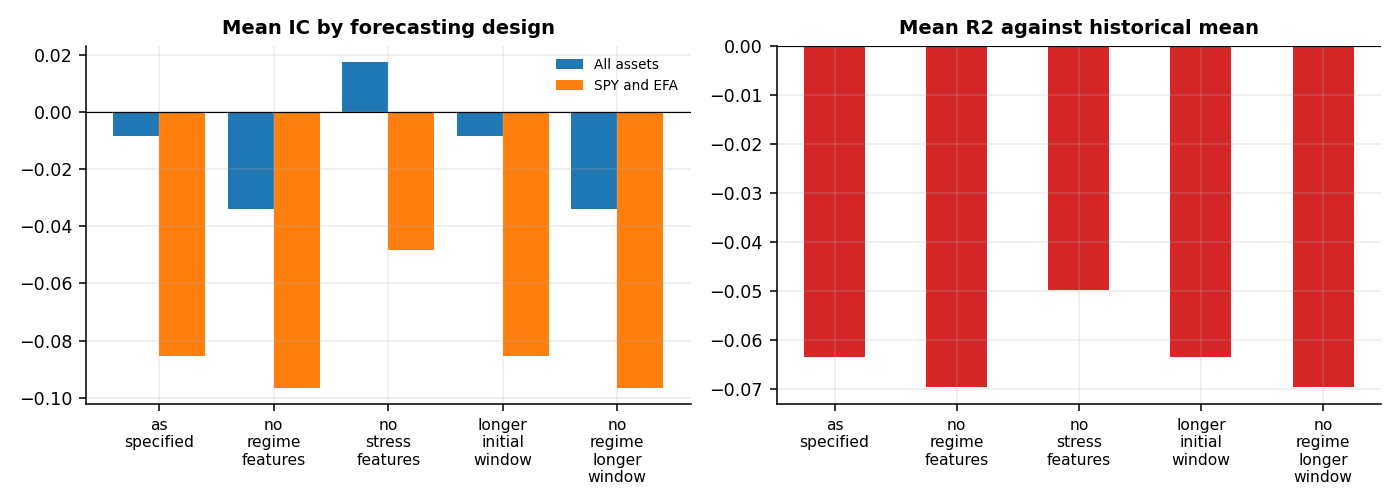

In [3]:
from IPython.display import Image

Image(str(P.figures / "12_ic_diagnostics.png"))

In [4]:
pd.read_csv(P.tables / "deflated_sharpe.csv")

,strategy,Sharpe,BenchmarkSharpe,DSR,Trials
0,BL_ML_Regime,0.844414,0.077703,0.998833,5
1,BL_ML_Regime,0.844414,0.102592,0.998387,10
2,BL_ML_Regime_IC,0.860644,0.077703,0.998994,5
3,BL_ML_Regime_IC,0.860644,0.102592,0.998606,10
4,BL_ML_NoRegime,0.862048,0.077703,0.998991,5
5,BL_ML_NoRegime,0.862048,0.102592,0.998603,10


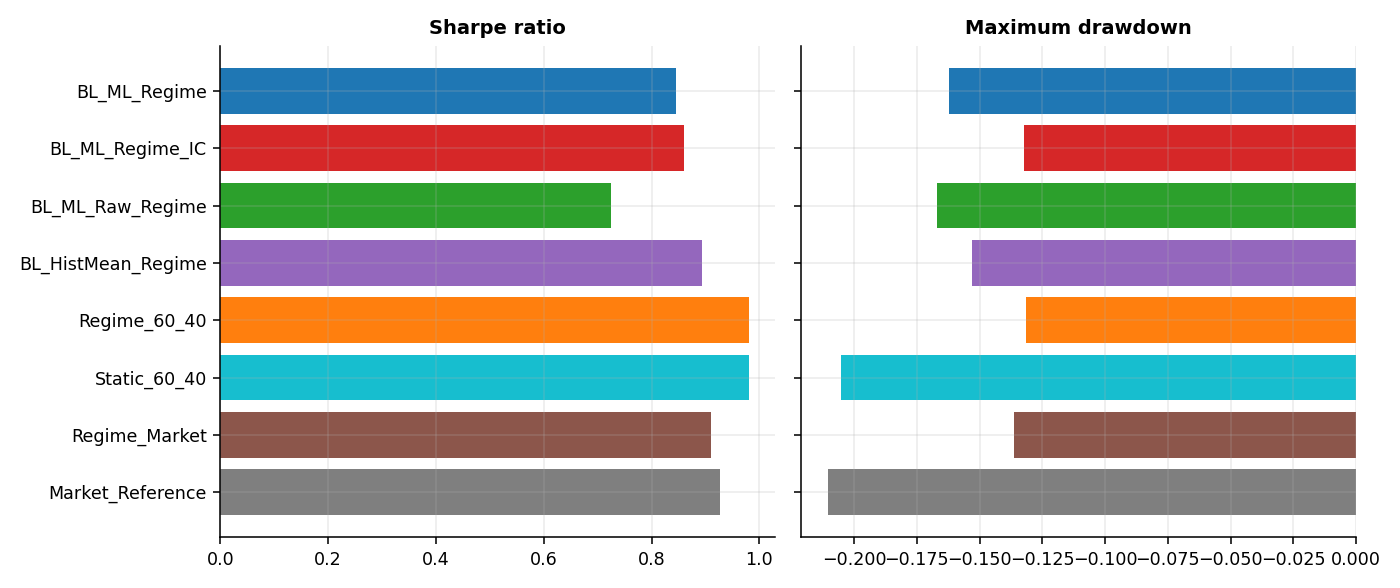

In [5]:
from IPython.display import Image

Image(str(P.figures / "14_overlay_ablation.png"))

In [6]:
pd.read_csv(P.tables / "lstm_repair.csv")

,Asset,n_oos,Disp_raw,R2OOS_raw,IC_raw,Disp_fixed,R2OOS_fixed,IC_fixed
0,BTC-USD,83,0.908460,-1.143499,-0.152974,0.376352,-0.287887,-0.186642
1,DBC,187,1.571743,-2.558854,-0.019832,0.341697,-0.111408,-0.032128
2,EFA,211,2.057775,-3.441643,-0.021512,0.324490,-0.120353,-0.071426
3,ETH-USD,46,1.079048,-1.190229,0.251681,0.513431,-0.306366,0.211964
4,GLD,201,1.505301,-2.778237,-0.105604,0.279617,-0.059370,-0.023613
5,HYG,173,2.530111,-6.710572,-0.041341,0.445434,-0.246705,0.014984
6,IEF,211,2.641537,-6.946565,0.035431,0.272978,-0.116698,0.003390
7,SPY,211,2.087700,-3.750995,0.007026,0.307083,-0.134376,-0.131225
8,TLT,211,2.393833,-5.791665,0.034890,0.241544,-0.051528,0.054284


In [7]:
pd.read_csv(P.tables / "skill_by_period.csv")

,Period,Forecast,MeanIC,MeanR2OOS,AssetsPositiveR2,Assets
0,full,xgb,0.008995,-0.206362,1,9
1,full,rf,-0.010653,-0.116163,0,9
2,full,ridge,-0.081400,-0.057842,1,9
3,full,lstm,-0.017823,-0.159410,0,9
4,full,pooled_ridge,-0.059822,-0.065613,1,9
5,full,pooled_xgb,-0.035670,-0.098632,2,9
6,full,ensemble_equal,-0.017716,-0.061443,0,9
7,full,ensemble_stacked,-0.046650,-0.090941,0,9
8,full,stack_all,-0.073495,-0.056363,0,9
9,full,ensemble_final,-0.103892,-0.013857,1,9


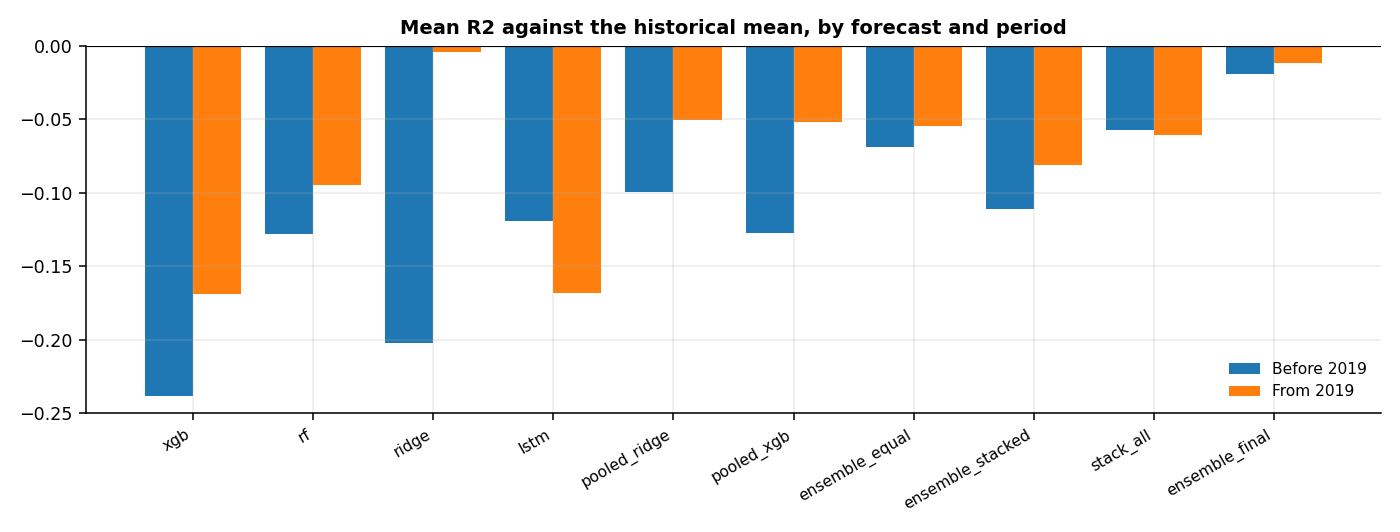

In [8]:
from IPython.display import Image

Image(str(P.figures / "15_forecast_repair.png"))

In [9]:
pd.read_csv(P.tables / "period_split.csv")

,strategy,period,AnnReturn,AnnVol,Sharpe,MaxDrawdown,Months
0,BL_ML_Regime,development,0.062399,0.063093,0.932741,-0.075405,120
1,BL_ML_Regime,holdout,0.095488,0.088093,0.778482,-0.162349,91
2,BL_ML_Regime_IC,development,0.059943,0.060583,0.930753,-0.073431,120
3,BL_ML_Regime_IC,holdout,0.092309,0.080881,0.803970,-0.132485,91
4,BL_ML_NoRegime,development,0.076611,0.076335,0.957766,-0.082461,120
5,BL_ML_NoRegime,holdout,0.117699,0.113406,0.804345,-0.228490,91
6,BL_ML_Raw_Regime,development,0.060244,0.067479,0.845631,-0.078637,120
7,BL_ML_Raw_Regime,holdout,0.084778,0.094591,0.626601,-0.167073,91
8,BL_HistMean_Regime,development,0.066602,0.061802,1.015285,-0.065663,120
9,BL_HistMean_Regime,holdout,0.096971,0.087314,0.800458,-0.153128,91


In [10]:
pd.read_csv(P.tables / "window_robustness.csv")

,Unnamed: 0,Sharpe_main,Sharpe_crisis_window,MaxDD_main,MaxDD_crisis_window,Months_main,Months_crisis_window
0,BL_ML_Regime,0.844414,0.713631,-0.162349,-0.171732,211.0,235.0
1,BL_ML_Regime_IC,0.860644,0.704956,-0.132485,-0.168795,211.0,235.0
2,BL_ML_NoRegime,0.862048,0.683593,-0.228490,-0.263664,211.0,235.0
3,BL_ML_Raw_Regime,0.725196,0.755404,-0.167073,-0.185326,211.0,235.0
4,BL_HistMean_Regime,0.893913,0.758701,-0.153128,-0.171732,211.0,235.0
5,Market_Reference,0.926883,0.688666,-0.210603,-0.314202,211.0,235.0
6,Equal_Weight,0.743854,0.695986,-0.235862,-0.286884,211.0,235.0
7,Static_60_40,0.980462,0.717282,-0.205222,-0.294934,211.0,235.0
8,Inverse_Vol,0.748663,0.671198,-0.177275,-0.184627,211.0,235.0
9,MeanVariance_LW,0.402221,0.390809,-0.369744,-0.469219,211.0,235.0


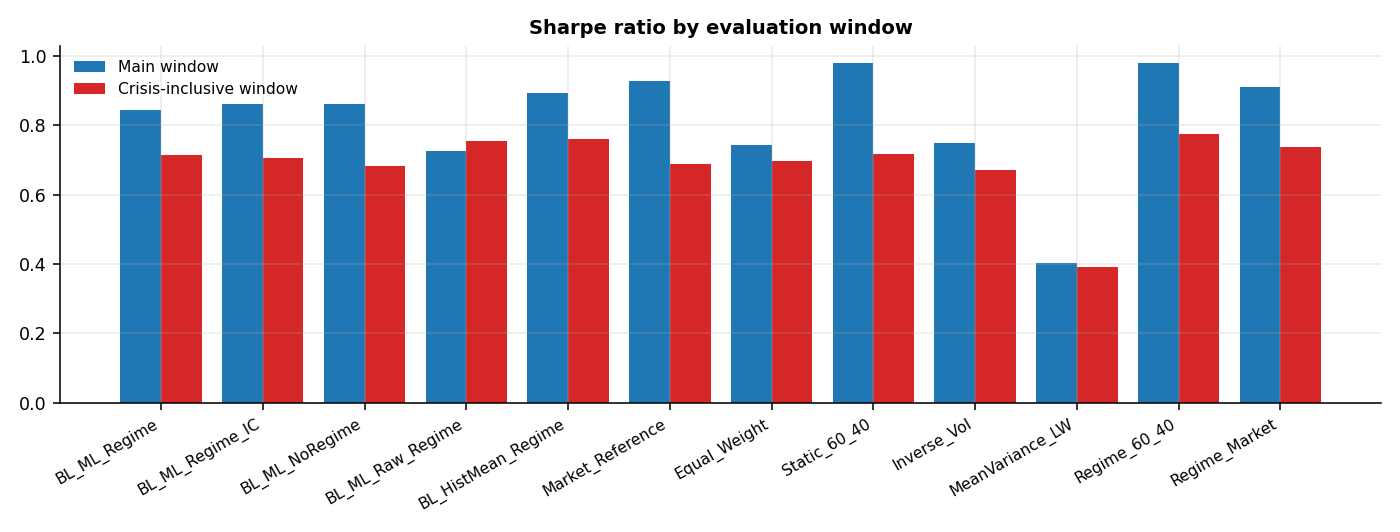

In [11]:
from IPython.display import Image

Image(str(P.figures / "16_window_robustness.png"))

In [12]:
pd.read_csv(P.tables / "prior_comparison.csv")

,Prior,Variant,Sharpe,Sharpe_PriorPortfolio,Diff,CI_low,CI_high,p_value,MaxDrawdown,MaxDrawdown_PriorPortfolio
0,reference,BL_ML_Regime,0.844414,0.926883,-0.082469,-0.253364,0.067722,0.324919,-0.162349,-0.210603
1,reference,BL_ML_Regime_IC,0.860644,0.926883,-0.066240,-0.199751,0.052147,0.309173,-0.132485,-0.210603
2,reference,BL_HistMean_Regime,0.893913,0.926883,-0.032970,-0.194031,0.110077,0.677831,-0.153128,-0.210603
3,equal,BL_ML_Regime,0.614623,0.743854,-0.129230,-0.283757,0.012109,0.091727,-0.177833,-0.235862
4,equal,BL_ML_Regime_IC,0.653661,0.743854,-0.090193,-0.218675,0.029461,0.160710,-0.153910,-0.235862
5,equal,BL_HistMean_Regime,0.651268,0.743854,-0.092585,-0.248634,0.051611,0.240690,-0.169302,-0.235862
6,inverse_vol,BL_ML_Regime,0.630722,0.750727,-0.120005,-0.319665,0.045465,0.218445,-0.144156,-0.174322
7,inverse_vol,BL_ML_Regime_IC,0.692929,0.750727,-0.057798,-0.207339,0.073723,0.430142,-0.111864,-0.174322
8,inverse_vol,BL_HistMean_Regime,0.693016,0.750727,-0.057711,-0.250055,0.103419,0.532117,-0.134237,-0.174322


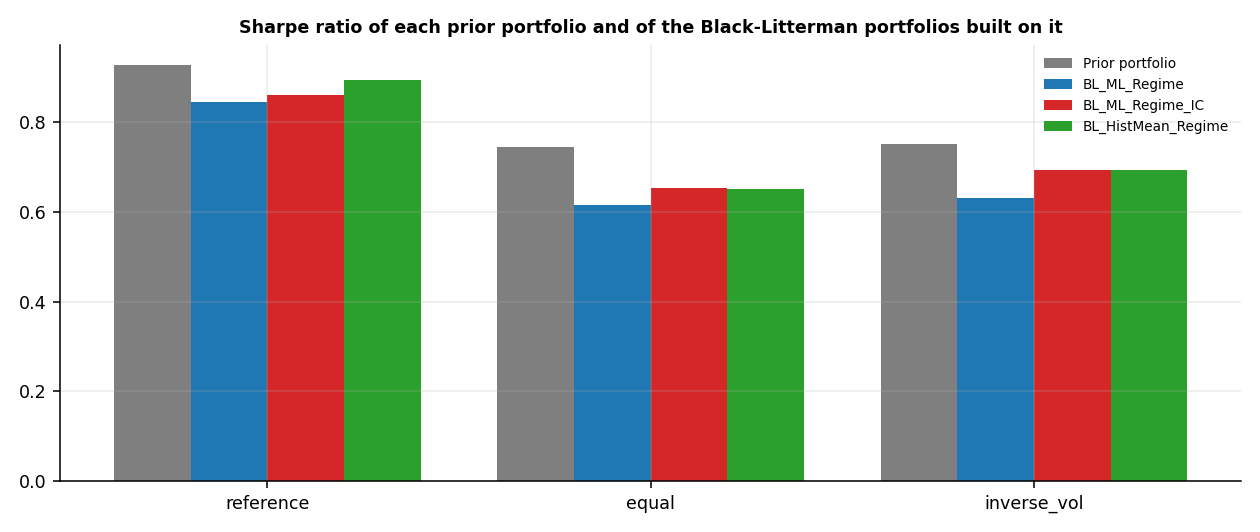

In [13]:
from IPython.display import Image

Image(str(P.figures / "17_prior_comparison.png"))

In [14]:
pd.read_csv(P.tables / "holdout_status.csv")

,freeze_date,spec_hash,spec_unchanged,months_since_freeze,inference_possible
0,2026-07-31,94b4989460889eca,True,0,False


In [15]:
pd.read_csv(P.tables / "sensitivity.csv")

,Parameter,Value,IsDefault,Variant,Sharpe,AnnVol,MaxDrawdown,AnnTurnover,AvgCash,Sharpe_60_40
0,tau,0.025,False,BL_ML_Regime,0.869349,0.073365,-0.149339,1.856904,0.156250,0.980462
1,tau,0.025,False,BL_ML_Regime_IC,0.864867,0.071265,-0.133316,1.302872,0.172465,0.980462
2,tau,0.05,True,BL_ML_Regime,0.844414,0.074857,-0.162349,2.363050,0.162119,0.980462
3,tau,0.05,True,BL_ML_Regime_IC,0.860644,0.070029,-0.132485,1.407590,0.182136,0.980462
4,tau,0.1,False,BL_ML_Regime,0.796729,0.078387,-0.175251,2.988129,0.164666,0.980462
5,tau,0.1,False,BL_ML_Regime_IC,0.850326,0.068102,-0.130938,1.576629,0.200737,0.980462
6,tau,0.2,False,BL_ML_Regime,0.706628,0.084616,-0.188567,3.601666,0.160578,0.980462
7,tau,0.2,False,BL_ML_Regime_IC,0.860413,0.064677,-0.128267,1.777573,0.230496,0.980462
8,base_delta,1.5,False,BL_ML_Regime,0.780855,0.082870,-0.180226,3.009799,0.130538,0.980462
9,base_delta,1.5,False,BL_ML_Regime_IC,0.846432,0.070857,-0.135684,1.592017,0.171587,0.980462


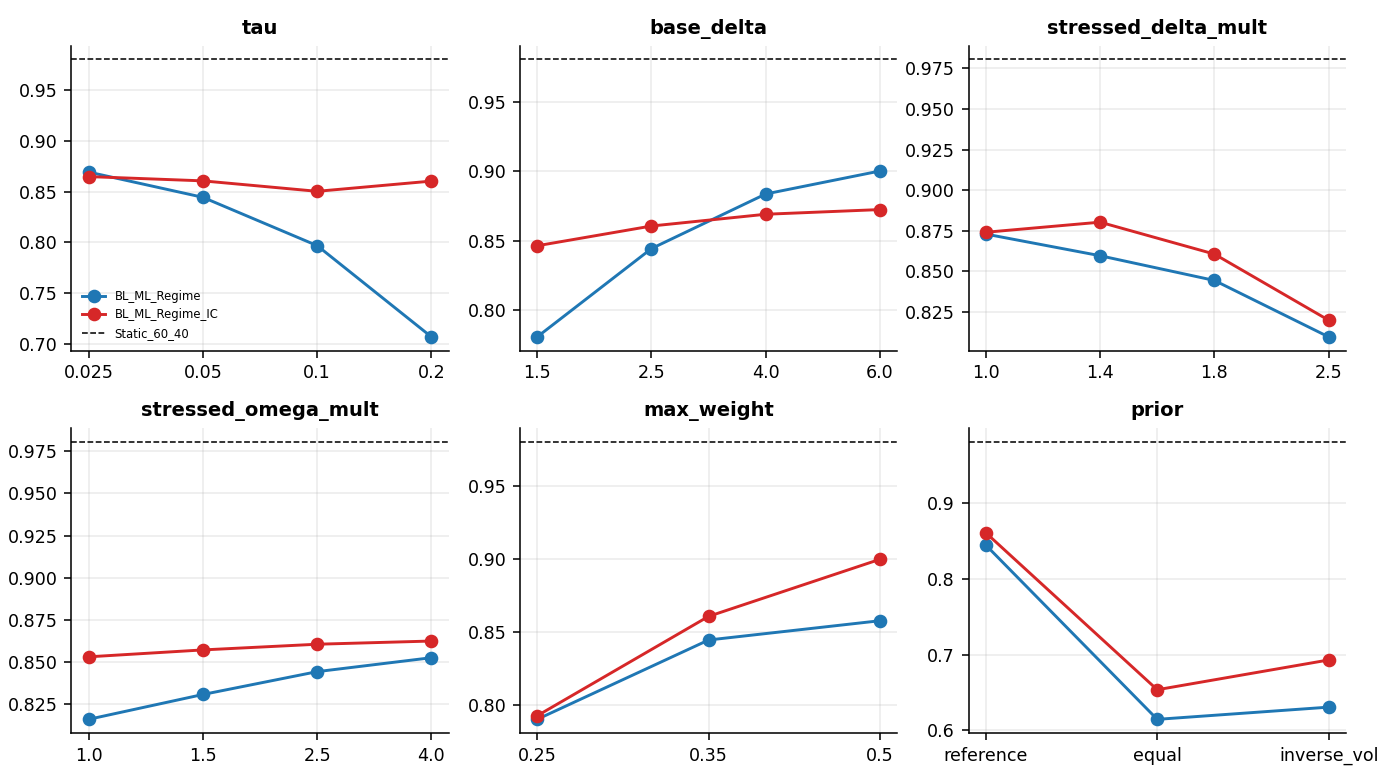

In [16]:
from IPython.display import Image

Image(str(P.figures / "13_sensitivity.png"))